# 📘 Week 5 Practical and Revision Workbook

## Machine Learning Regression

This workbook connects the six Week 5 notes through reproducible engineering activities.
Begin the guided explorations in Monday's workshop, complete the problem-solving tasks in
Wednesday's practical, and finish the revision section at home.


# 🧭 Weekly workflow and expected effort

| Stage | Suggested use | Approximate time |
|---|---|---:|
| Before Monday | Run the six topic notebooks and note questions | 2 hours |
| Monday workshop | Guided Activities 1A–6A, live demonstrations and discussion | 2 hours |
| Wednesday practical | Problem-solving Activities 1B–6B with tutor support | 2 hours |
| Revision | Finish problems, complete test-style questions and review explanations | 3 hours |

The activities follow **Predict → Change or implement → Run → Inspect → Explain → Validate**.


# ✅ Before Wednesday's practical

You should have:

- run the Week 5.1–5.6 notes from top to bottom;
- attempted each guided **A** activity at least once;
- saved the figures or results you want to discuss; and
- written a short prediction before changing each `TODO` value.

All datasets are synthetic and created inside this workbook. No downloads are required.


# 🎯 Learning objectives

By completing this workbook, you should be able to:

- construct and interpret linear, tree, SVR and neural-network regression models;
- connect model flexibility and hyperparameters to underfitting and overfitting;
- select metrics and baselines that match an engineering decision;
- identify target leakage, duplicate events and unsupported evaluation designs;
- choose random, grouped or time-ordered splitting for a stated deployment task; and
- justify a model and data workflow using numerical and graphical evidence.


# 📚 Week 5 notes map

| Workbook pair | Supporting notes | Main skill |
|---|---|---|
| 1A–1B | 5.1 Linear Regression | Coefficients, transformed features and validation |
| 2A–2B | 5.2 Decision Tree Regression | Tree complexity and defensible selection |
| 3A–3B | 5.3 Support Vector Regression | Scaling, `C`, `epsilon` and `gamma` |
| 4A–4B | 5.4 Neural Network Regression | Architecture, regularisation and repeatability |
| 5A–5B | 5.5 Evaluating Regression Performance | Metrics, baselines and consequence-aware choice |
| 6A–6B | 5.6 Training Data Evaluation and Selection | Leakage, identity, grouping and time |


# 🧰 Shared setup

Run the next two cells before beginning any activity. They create a synthetic fan-fleet
dataset and reusable evaluation functions. Each row represents one operating run from one
physical fan unit.

The data is designed for teaching. It is not measured equipment data and must not be used for
engineering design.


In [ ]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

pd.set_option("display.precision", 3)


def regression_metrics(y_true, y_pred):
    # Return three labelled regression metrics.
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }


def metric_table(y_true, predictions):
    # Compare named prediction arrays using the same observations.
    return pd.DataFrame({
        name: regression_metrics(y_true, prediction)
        for name, prediction in predictions.items()
    }).T


def plot_prediction_diagnostic(y_true, y_pred, title):
    # Show agreement and residual structure for one selected regression model.
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    residual = y_true - y_pred
    limits = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]

    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
    axes[0].scatter(y_true, y_pred, alpha=0.7)
    axes[0].plot(limits, limits, color="black", linestyle="--", label="ideal")
    axes[0].set(xlabel="Observed target", ylabel="Predicted target", title=f"{title}: agreement")
    axes[0].legend(); axes[0].grid(True)
    axes[1].scatter(y_pred, residual, alpha=0.7)
    axes[1].axhline(0, color="black", linestyle="--")
    axes[1].set(xlabel="Predicted target", ylabel="Residual: observed − predicted", title=f"{title}: residuals")
    axes[1].grid(True)
    fig.tight_layout(); plt.show()


In [ ]:
rng = np.random.default_rng(5001)
fan_units = [f"F{number:02d}" for number in range(1, 9)]
run_dates = pd.date_range("2026-02-02", periods=60, freq="D")
unit_efficiency_offset = dict(zip(fan_units, rng.normal(0.0, 0.035, len(fan_units))))

fan_records = []
event_number = 0
for unit_number, unit_id in enumerate(fan_units):
    operating_hours = rng.uniform(200, 1400)
    for day_number, timestamp in enumerate(run_dates):
        event_number += 1
        seasonal = np.sin(2 * np.pi * day_number / len(run_dates))
        airflow_m3s = np.clip(5.0 + 1.25 * seasonal + rng.normal(0, 0.75), 2.2, 7.8)
        pressure_pa = np.clip(820 - 42 * (airflow_m3s - 5) + rng.normal(0, 75), 480, 1150)
        ambient_temp_c = 23 + 7 * seasonal + rng.normal(0, 1.5)
        run_duration_h = rng.uniform(1.0, 6.0)
        operating_hours += run_duration_h
        vibration_mm_s = np.clip(
            0.85 + 0.00028 * operating_hours + rng.normal(0, 0.12), 0.4, None
        )
        efficiency = np.clip(
            0.77
            + unit_efficiency_offset[unit_id]
            - 0.000018 * operating_hours
            - 0.012 * (airflow_m3s - 5.1) ** 2
            - 0.002 * np.maximum(ambient_temp_c - 27, 0),
            0.57,
            0.84,
        )
        hydraulic_power_kw = airflow_m3s * pressure_pa / 1000
        electrical_power_kw = (
            hydraulic_power_kw / efficiency
            + 1.6
            + 0.055 * airflow_m3s ** 2
            + rng.normal(0, 0.28)
        )
        fan_records.append({
            "event_id": f"RUN{event_number:04d}",
            "timestamp": timestamp + pd.Timedelta(hours=8 + unit_number / 2),
            "unit_id": unit_id,
            "airflow_m3s": airflow_m3s,
            "pressure_pa": pressure_pa,
            "ambient_temp_c": ambient_temp_c,
            "vibration_mm_s": vibration_mm_s,
            "operating_hours": operating_hours,
            "run_duration_h": run_duration_h,
            "power_kw": electrical_power_kw,
            "post_run_energy_kwh": electrical_power_kw * run_duration_h + rng.normal(0, 0.05),
        })

fan_data = pd.DataFrame(fan_records)
fan_data["airflow_squared"] = fan_data["airflow_m3s"] ** 2
fan_data["hydraulic_power_kw"] = fan_data["airflow_m3s"] * fan_data["pressure_pa"] / 1000

missing_temperature = rng.choice(fan_data.index, 12, replace=False)
missing_vibration = rng.choice(fan_data.index, 16, replace=False)
fan_data.loc[missing_temperature, "ambient_temp_c"] = np.nan
fan_data.loc[missing_vibration, "vibration_mm_s"] = np.nan

fan_train_index, fan_validation_index = train_test_split(
    np.arange(len(fan_data)), test_size=0.25, random_state=50
)

fan_numeric_features = [
    "airflow_m3s", "pressure_pa", "ambient_temp_c", "vibration_mm_s", "operating_hours"
]

display(fan_data.head())
print(f"Rows: {len(fan_data)} | physical fan units: {fan_data['unit_id'].nunique()}")


,event_id,timestamp,unit_id,airflow_m3s,pressure_pa,ambient_temp_c,vibration_mm_s,operating_hours,run_duration_h,power_kw,post_run_energy_kwh,airflow_squared,hydraulic_power_kw
0,RUN0001,2026-02-02 08:00:00,F01,5.679,839.193,21.164,0.958,351.728,3.455,9.260,32.034,32.250,4.766
1,RUN0002,2026-02-03 08:00:00,F01,3.977,858.904,21.624,0.957,357.288,5.561,6.726,37.489,15.814,3.416
2,RUN0003,2026-02-04 08:00:00,F01,5.472,895.202,23.267,1.118,362.807,5.519,9.354,51.644,29.938,4.898
3,RUN0004,2026-02-05 08:00:00,F01,3.735,885.736,24.892,0.987,367.216,4.409,6.679,29.450,13.948,3.308
4,RUN0005,2026-02-06 08:00:00,F01,5.488,874.709,25.580,0.956,372.926,5.710,8.891,50.729,30.118,4.800


Rows: 480 | physical fan units: 8


# 🟧 Monday workshop — guided exploration

Activities 1A–6A contain valid starter values. Before changing a `TODO`, predict the effect on
the model or metric. Run the cell, inspect the output, then explain whether your prediction was
supported.


## Activity 1A — Linear regression and an influential calibration point

A force sensor is calibrated using known loads. Change `TODO_OUTLIER_SHIFT_KN` to `0`, `4` and
`10`. For each value, inspect the fitted line, slope, validation MAE and residual at the altered
point.

**Predict first:** which quantity will change most—the slope, intercept or validation MAE?


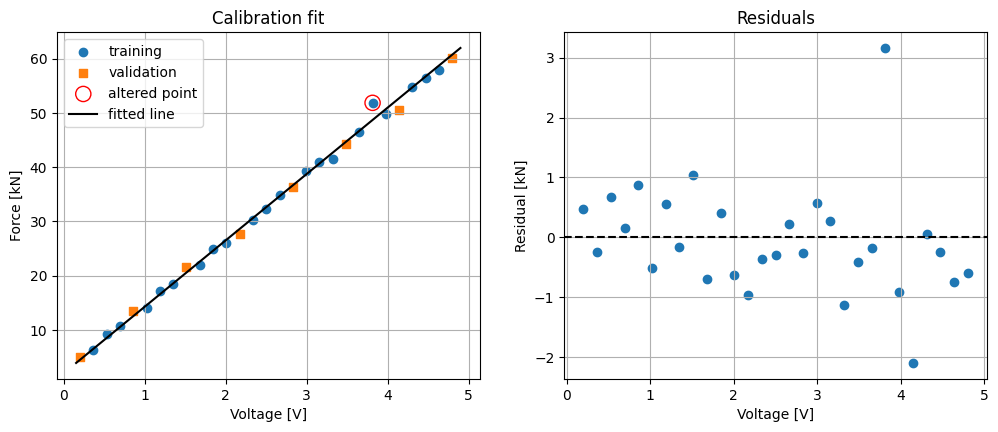

,result
intercept_kN,2.074
slope_kN_per_V,12.225
validation_MAE_kN,0.840
altered_point_residual_kN,3.160


In [ ]:
TODO_OUTLIER_SHIFT_KN = 4.0  # TODO: try 0.0, 4.0 and 10.0

rng_1a = np.random.default_rng(5101)
voltage_v = np.linspace(0.2, 4.8, 29)
force_kn = 2.5 + 12.0 * voltage_v + rng_1a.normal(0, 0.55, len(voltage_v))
force_kn[22] += TODO_OUTLIER_SHIFT_KN

calibration_1a = pd.DataFrame({"voltage_v": voltage_v, "force_kn": force_kn})
train_1a = calibration_1a.index % 4 != 0
validation_1a = ~train_1a

model_1a = LinearRegression().fit(
    calibration_1a.loc[train_1a, ["voltage_v"]], calibration_1a.loc[train_1a, "force_kn"]
)
prediction_1a = model_1a.predict(calibration_1a.loc[validation_1a, ["voltage_v"]])
grid_1a = pd.DataFrame({"voltage_v": np.linspace(0.15, 4.9, 200)})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(calibration_1a.loc[train_1a, "voltage_v"], calibration_1a.loc[train_1a, "force_kn"], label="training")
axes[0].scatter(calibration_1a.loc[validation_1a, "voltage_v"], calibration_1a.loc[validation_1a, "force_kn"], marker="s", label="validation")
axes[0].scatter(calibration_1a.loc[22, "voltage_v"], calibration_1a.loc[22, "force_kn"], s=120, facecolors="none", edgecolors="red", label="altered point")
axes[0].plot(grid_1a["voltage_v"], model_1a.predict(grid_1a), color="black", label="fitted line")
axes[0].set(xlabel="Voltage [V]", ylabel="Force [kN]", title="Calibration fit")
axes[0].legend(); axes[0].grid(True)

residual_1a = calibration_1a["force_kn"] - model_1a.predict(calibration_1a[["voltage_v"]])
axes[1].scatter(calibration_1a["voltage_v"], residual_1a)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(xlabel="Voltage [V]", ylabel="Residual [kN]", title="Residuals")
axes[1].grid(True)
plt.show()

pd.Series({
    "intercept_kN": model_1a.intercept_,
    "slope_kN_per_V": model_1a.coef_[0],
    "validation_MAE_kN": mean_absolute_error(calibration_1a.loc[validation_1a, "force_kn"], prediction_1a),
    "altered_point_residual_kN": residual_1a.loc[22],
}, name="result").to_frame()


**Explain:** Why can one unusual point influence a least-squares fit? Would deleting it be
justified without checking the experiment log?


## Activity 2A — Decision-tree complexity

Change the tree depth and minimum leaf size. The one-feature plot makes the tree's rectangular
steps visible; the table compares training and validation error.

Try shallow, moderate and deep settings. **Predict first:** which setting will have the lowest
training error, and which is most likely to generalise?


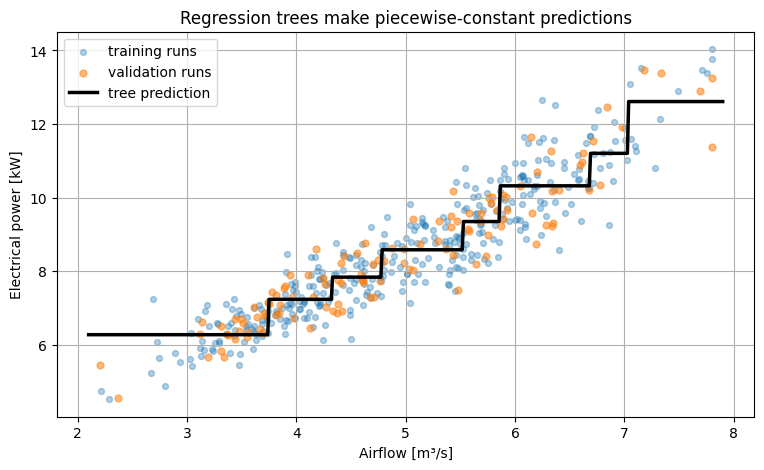

,subset,MAE_kW
0,training,0.534
1,validation,0.509


In [ ]:
TODO_MAX_DEPTH = 3          # TODO: try 1, 3, 6 and None
TODO_MIN_SAMPLES_LEAF = 10  # TODO: try 1, 5, 10 and 25

tree_2a = DecisionTreeRegressor(
    max_depth=TODO_MAX_DEPTH,
    min_samples_leaf=TODO_MIN_SAMPLES_LEAF,
    random_state=52,
)
tree_2a.fit(fan_data.loc[fan_train_index, ["airflow_m3s"]], fan_data.loc[fan_train_index, "power_kw"])

train_prediction_2a = tree_2a.predict(fan_data.loc[fan_train_index, ["airflow_m3s"]])
validation_prediction_2a = tree_2a.predict(fan_data.loc[fan_validation_index, ["airflow_m3s"]])
airflow_grid_2a = pd.DataFrame({"airflow_m3s": np.linspace(2.1, 7.9, 500)})

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(fan_data.loc[fan_train_index, "airflow_m3s"], fan_data.loc[fan_train_index, "power_kw"], s=18, alpha=0.35, label="training runs")
ax.scatter(fan_data.loc[fan_validation_index, "airflow_m3s"], fan_data.loc[fan_validation_index, "power_kw"], s=24, alpha=0.55, label="validation runs")
ax.plot(airflow_grid_2a["airflow_m3s"], tree_2a.predict(airflow_grid_2a), color="black", linewidth=2.5, label="tree prediction")
ax.set(xlabel="Airflow [m³/s]", ylabel="Electrical power [kW]", title="Regression trees make piecewise-constant predictions")
ax.grid(True); ax.legend(); plt.show()

pd.DataFrame({
    "subset": ["training", "validation"],
    "MAE_kW": [
        mean_absolute_error(fan_data.loc[fan_train_index, "power_kw"], train_prediction_2a),
        mean_absolute_error(fan_data.loc[fan_validation_index, "power_kw"], validation_prediction_2a),
    ],
})


**Explain:** What visual evidence indicates underfitting? What numerical pattern indicates
overfitting? Why does a tree not extrapolate a rising trend beyond its final split?


## Activity 3A — SVR scaling and hyperparameters

The five fan features use very different numerical scales. Change one `TODO` at a time and
record the validation MAE and number of support vectors.

Suggested comparisons: scaling on/off; `C = 1, 30, 150`; `epsilon = 0.05, 0.3, 1.0`; and
`gamma = "scale", 0.02, 0.5`.


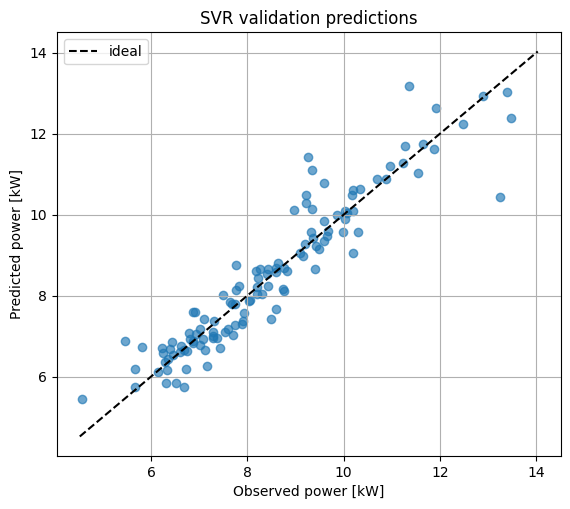

,result
MAE,0.433
RMSE,0.630
R2,0.881
support_vectors,193.000


In [ ]:
TODO_USE_SCALING = True  # TODO: compare True and False
TODO_C = 30.0            # TODO: try 1, 30 and 150
TODO_EPSILON = 0.30      # TODO: try 0.05, 0.30 and 1.00
TODO_GAMMA = "scale"     # TODO: try "scale", 0.02 and 0.50

def build_svr_3a(use_scaling, C, epsilon, gamma):
    svr = SVR(kernel="rbf", C=C, epsilon=epsilon, gamma=gamma)
    if use_scaling:
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("svr", svr),
        ])
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("svr", svr),
    ])


svr_3a = build_svr_3a(TODO_USE_SCALING, TODO_C, TODO_EPSILON, TODO_GAMMA)
svr_3a.fit(fan_data.loc[fan_train_index, fan_numeric_features], fan_data.loc[fan_train_index, "power_kw"])
prediction_3a = svr_3a.predict(fan_data.loc[fan_validation_index, fan_numeric_features])
support_count_3a = len(svr_3a.named_steps["svr"].support_)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(fan_data.loc[fan_validation_index, "power_kw"], prediction_3a, alpha=0.65)
limits_3a = [fan_data["power_kw"].min(), fan_data["power_kw"].max()]
ax.plot(limits_3a, limits_3a, color="black", linestyle="--", label="ideal")
ax.set(xlabel="Observed power [kW]", ylabel="Predicted power [kW]", title="SVR validation predictions")
ax.grid(True); ax.legend(); plt.show()

pd.Series({
    **regression_metrics(fan_data.loc[fan_validation_index, "power_kw"], prediction_3a),
    "support_vectors": support_count_3a,
}, name="result").to_frame()


**Explain:** Why can unscaled pressure values dominate distances? How do larger `epsilon` and
larger `C` change the tolerance–complexity trade-off?


## Activity 4A — Neural-network architecture, regularisation and seed

Change the hidden-layer architecture, `alpha` and random seed. The loss curve shows the
optimisation path; validation predictions show generalisation.

Try `(10,)`, `(30,)` and `(30, 15)`, then repeat one architecture with several seeds.


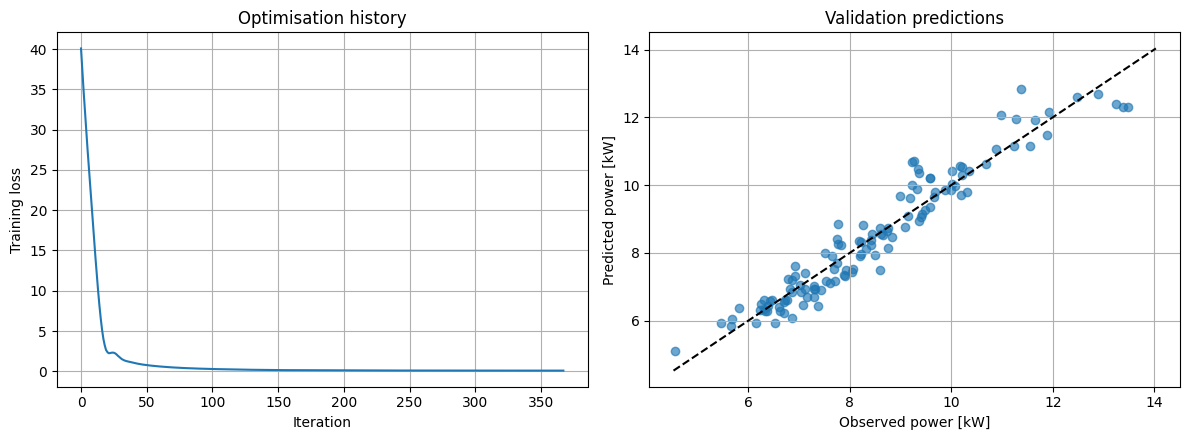

,result
MAE,0.395
RMSE,0.513
R2,0.921
iterations,368.000


In [ ]:
TODO_HIDDEN_LAYERS = (30,)  # TODO: try (10,), (30,) and (30, 15)
TODO_ALPHA = 0.001          # TODO: try 0.0001, 0.001 and 0.1
TODO_RANDOM_SEED = 54       # TODO: change the seed and compare

def build_mlp_4a(hidden_layers, alpha, seed):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("mlp", MLPRegressor(
            hidden_layer_sizes=hidden_layers,
            alpha=alpha,
            random_state=seed,
            max_iter=1000,
            learning_rate_init=0.01,
            early_stopping=True,
            validation_fraction=0.18,
            n_iter_no_change=35,
        )),
    ])


mlp_4a = build_mlp_4a(TODO_HIDDEN_LAYERS, TODO_ALPHA, TODO_RANDOM_SEED)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    mlp_4a.fit(fan_data.loc[fan_train_index, fan_numeric_features], fan_data.loc[fan_train_index, "power_kw"])
prediction_4a = mlp_4a.predict(fan_data.loc[fan_validation_index, fan_numeric_features])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(mlp_4a.named_steps["mlp"].loss_curve_)
axes[0].set(xlabel="Iteration", ylabel="Training loss", title="Optimisation history")
axes[0].grid(True)
axes[1].scatter(fan_data.loc[fan_validation_index, "power_kw"], prediction_4a, alpha=0.65)
axes[1].plot(limits_3a, limits_3a, color="black", linestyle="--")
axes[1].set(xlabel="Observed power [kW]", ylabel="Predicted power [kW]", title="Validation predictions")
axes[1].grid(True)
fig.tight_layout(); plt.show()

pd.Series({
    **regression_metrics(fan_data.loc[fan_validation_index, "power_kw"], prediction_4a),
    "iterations": mlp_4a.named_steps["mlp"].n_iter_,
}, name="result").to_frame()


**Explain:** Why is one successful random seed insufficient evidence? What would a flat or
unstable loss curve suggest?


## Activity 5A — MAE and RMSE react differently

Two candidate models have small errors on most runs. Change the single large error and inspect
how MAE and RMSE respond.

**Predict first:** which metric will change faster as the large error grows?


,MAE,RMSE
even errors,3.000,3.000
one large error,1.917,3.594


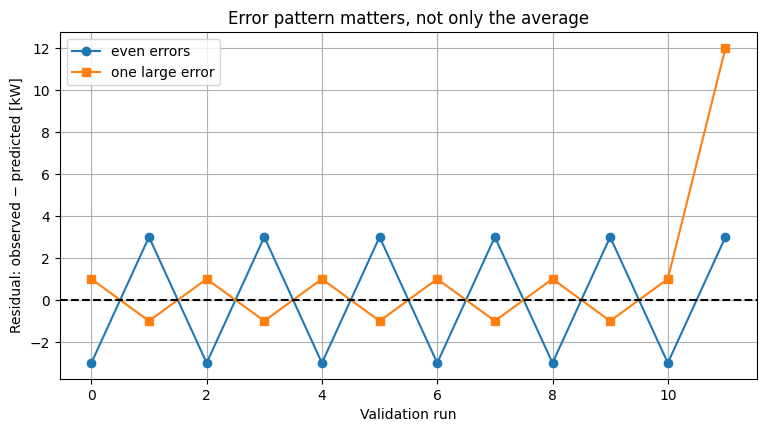

In [ ]:
TODO_LARGE_ERROR_KW = 12.0  # TODO: try 2, 6, 12 and 24

observed_5a = np.full(12, 50.0)
errors_even_5a = np.array([-3, 3] * 6, dtype=float)
errors_one_large_5a = np.array([1, -1, 1, -1, 1, -1, 1, -1, 1, -1, 1, TODO_LARGE_ERROR_KW], dtype=float)
predictions_5a = {
    "even errors": observed_5a - errors_even_5a,
    "one large error": observed_5a - errors_one_large_5a,
}

display(metric_table(observed_5a, predictions_5a)[["MAE", "RMSE"]])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(errors_even_5a, marker="o", label="even errors")
ax.plot(errors_one_large_5a, marker="s", label="one large error")
ax.axhline(0, color="black", linestyle="--")
ax.set(xlabel="Validation run", ylabel="Residual: observed − predicted [kW]", title="Error pattern matters, not only the average")
ax.grid(True); ax.legend(); plt.show()


**Explain:** When would RMSE's additional sensitivity to a large error be useful? When might
MAE be easier to communicate?


## Activity 6A — Random, grouped or future split?

Change `TODO_SPLIT_KIND` among `"random"`, `"grouped"` and `"time"`. The same model is then
evaluated on:

- similar runs from represented fan units;
- entirely unseen fan units; or
- the final 25% of operating time.

Predict which split will be most difficult before running it.


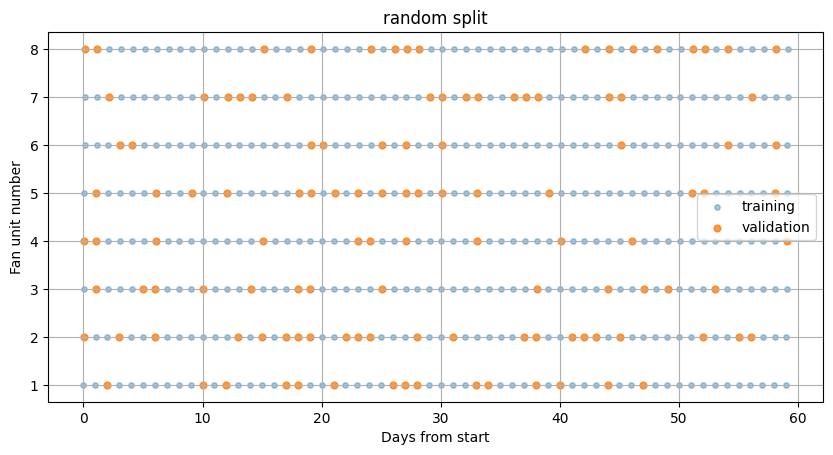

,result
training_rows,360.000
validation_rows,120.000
shared_units,8.000
MAE,0.409
RMSE,0.540
R2,0.915


In [ ]:
TODO_SPLIT_KIND = "random"  # TODO: use "random", "grouped" or "time"

def make_split_6a(data, split_kind):
    rows = np.arange(len(data))
    if split_kind == "random":
        return train_test_split(rows, test_size=0.25, random_state=56)
    if split_kind == "grouped":
        splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=56)
        return next(splitter.split(data, groups=data["unit_id"]))
    if split_kind == "time":
        ordered = np.argsort(data["timestamp"].to_numpy())
        boundary = int(0.75 * len(ordered))
        return ordered[:boundary], ordered[boundary:]
    raise ValueError("split_kind must be 'random', 'grouped' or 'time'")


train_6a, validation_6a = make_split_6a(fan_data, TODO_SPLIT_KIND)
model_6a = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("svr", SVR(C=30, epsilon=0.25)),
])
model_6a.fit(fan_data.iloc[train_6a][fan_numeric_features], fan_data.iloc[train_6a]["power_kw"])
prediction_6a = model_6a.predict(fan_data.iloc[validation_6a][fan_numeric_features])

train_units_6a = set(fan_data.iloc[train_6a]["unit_id"])
validation_units_6a = set(fan_data.iloc[validation_6a]["unit_id"])
day_6a = (fan_data["timestamp"] - fan_data["timestamp"].min()).dt.total_seconds() / 86400
unit_number_6a = fan_data["unit_id"].str[1:].astype(int)

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.scatter(day_6a.iloc[train_6a], unit_number_6a.iloc[train_6a], s=15, alpha=0.4, label="training")
ax.scatter(day_6a.iloc[validation_6a], unit_number_6a.iloc[validation_6a], s=24, alpha=0.8, label="validation")
ax.set(xlabel="Days from start", ylabel="Fan unit number", title=f"{TODO_SPLIT_KIND} split")
ax.set_yticks(range(1, 9)); ax.grid(True); ax.legend(); plt.show()

pd.Series({
    "training_rows": len(train_6a),
    "validation_rows": len(validation_6a),
    "shared_units": len(train_units_6a & validation_units_6a),
    **regression_metrics(fan_data.iloc[validation_6a]["power_kw"], prediction_6a),
}, name="result").to_frame()


**Explain:** What deployment question does your chosen split answer? Why is the lowest score
not automatically the most relevant score?


# 🟩 Wednesday practical — problem solving

Activities 1B–6B supply the data, imports and helper functions. The starter choices run without
errors but are not necessarily defensible answers. Use the hints progressively and justify
every final choice in engineering language.


## Activity 1B — Build a multiple linear regression model

**Problem:** predict fan power using a linear regression model. Decide which supplied features
provide a defensible balance of fit and interpretation. Compare your model with a mean
baseline and report coefficient units.

### Features available to you

| Feature | Meaning | Units | Available before the run? |
|---|---|---|---|
| `airflow_m3s` | Measured airflow | m³/s | Yes |
| `pressure_pa` | Fan pressure rise | Pa | Yes |
| `ambient_temp_c` | Ambient temperature | °C | Yes; some values are missing |
| `vibration_mm_s` | Vibration RMS | mm/s | Yes; some values are missing |
| `operating_hours` | Accumulated fan operating time | h | Yes |
| `airflow_squared` | `airflow_m3s ** 2`, allowing curvature | (m³/s)² | Yes; calculated from airflow |
| `hydraulic_power_kw` | `airflow × pressure / 1000`, a physical interaction | kW | Yes; calculated from two measurements |

Identifiers, timestamps, run duration and post-run energy also exist in the dataframe, but they
are not candidate numeric inputs for this task. The last two are unavailable before the run.

**Hints:**

1. Begin with `airflow_m3s`, `pressure_pa` and `ambient_temp_c`.
2. Record the baseline and linear-model validation MAE.
3. Add one candidate feature at a time; rerun and record whether validation MAE improves.
4. Inspect the selected model's observed-versus-predicted and residual plots.
5. Keep a feature only if you can explain its availability, units and engineering meaning.


,MAE,RMSE,R2
linear model,0.377,0.476,9.321e-01
mean baseline,1.484,1.828,-7.010e-04


Selected features: ['airflow_m3s', 'pressure_pa', 'ambient_temp_c']


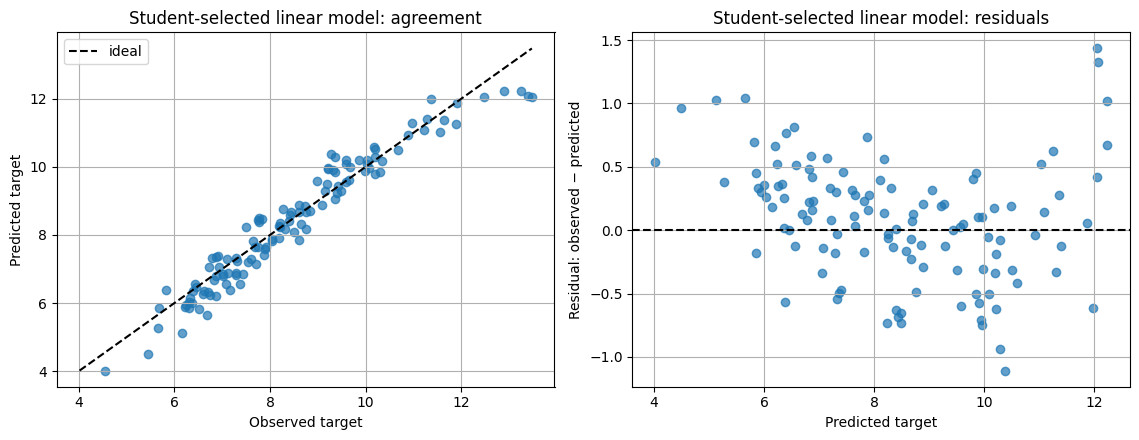

In [ ]:
# TODO: revise this feature list after testing the supplied alternatives.
selected_features_1b = ["airflow_m3s", "pressure_pa", "ambient_temp_c"]

def evaluate_linear_1b(feature_names):
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("linear", LinearRegression()),
    ])
    model.fit(fan_data.loc[fan_train_index, feature_names], fan_data.loc[fan_train_index, "power_kw"])
    pred = model.predict(fan_data.loc[fan_validation_index, feature_names])
    baseline = DummyRegressor(strategy="mean").fit(
        fan_data.loc[fan_train_index, feature_names], fan_data.loc[fan_train_index, "power_kw"]
    )
    baseline_pred = baseline.predict(fan_data.loc[fan_validation_index, feature_names])
    return model, metric_table(
        fan_data.loc[fan_validation_index, "power_kw"],
        {"linear model": pred, "mean baseline": baseline_pred},
    )


student_model_1b, student_metrics_1b = evaluate_linear_1b(selected_features_1b)
display(student_metrics_1b)
print("Selected features:", selected_features_1b)
student_prediction_1b = student_model_1b.predict(
    fan_data.loc[fan_validation_index, selected_features_1b]
)
plot_prediction_diagnostic(
    fan_data.loc[fan_validation_index, "power_kw"],
    student_prediction_1b,
    "Student-selected linear model",
)


**Your answer:** state your selected features, validation evidence, one coefficient with units,
and one limitation. Explain why a squared input does not make the model nonlinear in its
coefficients.


## Activity 2B — Select a defensible regression tree

**Problem:** choose the simplest tree whose validation MAE is within 5% of the best candidate.
Use all five numeric features. Do not choose from training error alone.

**Hints:**

1. Sort the supplied table by validation MAE.
2. Calculate `best_MAE = tree_candidates_2b["validation_MAE_kW"].min()`.
3. Calculate the acceptance limit `1.05 * best_MAE`.
4. Add a Boolean mask selecting rows whose validation MAE is below that limit.
5. Among eligible candidates, choose the shallowest tree; use larger leaves as a
   secondary preference.

Your selected tree is plotted automatically. Look for predictions that follow the overall
trend without producing unnecessarily small rectangular regions.


,max_depth,min_leaf,training_MAE_kW,validation_MAE_kW
22,NaN,12,0.383,0.401
18,7.0,12,0.383,0.401
13,5.0,6,0.336,0.408
14,5.0,12,0.388,0.408
17,7.0,6,0.293,0.413
21,NaN,6,0.283,0.420
12,5.0,2,0.324,0.433
9,4.0,6,0.401,0.435
10,4.0,12,0.418,0.437
8,4.0,2,0.394,0.466


,max_depth,min_leaf,training_MAE_kW,validation_MAE_kW
3,2.0,24,0.642,0.639


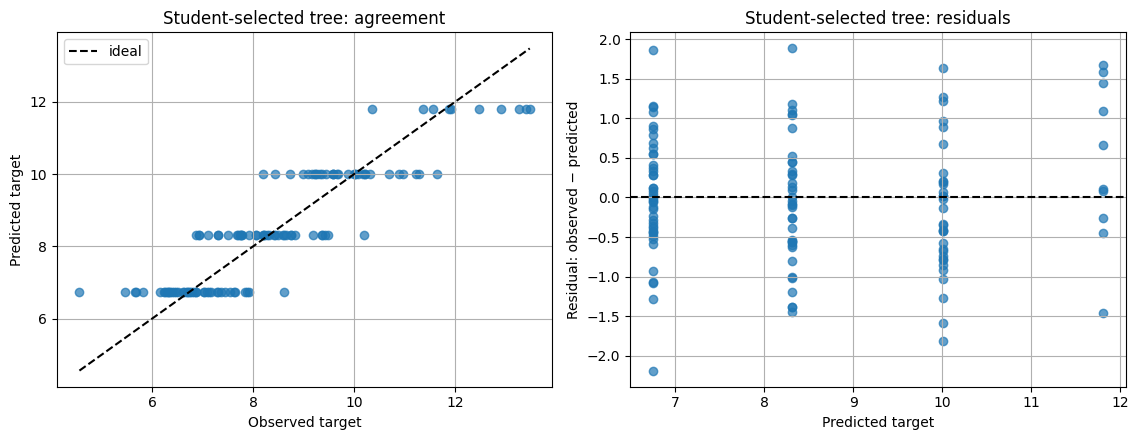

In [ ]:
def tree_search_2b():
    rows = []
    for depth in [2, 3, 4, 5, 7, None]:
        for leaf in [2, 6, 12, 24]:
            model = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("tree", DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf, random_state=52)),
            ])
            model.fit(fan_data.loc[fan_train_index, fan_numeric_features], fan_data.loc[fan_train_index, "power_kw"])
            train_pred = model.predict(fan_data.loc[fan_train_index, fan_numeric_features])
            val_pred = model.predict(fan_data.loc[fan_validation_index, fan_numeric_features])
            rows.append({
                "max_depth": depth, "min_leaf": leaf,
                "training_MAE_kW": mean_absolute_error(fan_data.loc[fan_train_index, "power_kw"], train_pred),
                "validation_MAE_kW": mean_absolute_error(fan_data.loc[fan_validation_index, "power_kw"], val_pred),
            })
    return pd.DataFrame(rows)


tree_candidates_2b = tree_search_2b()
display(tree_candidates_2b.sort_values("validation_MAE_kW").head(12))

selected_depth_2b = 2   # TODO: replace with your evidence-based choice
selected_leaf_2b = 24   # TODO: replace with your evidence-based choice
selected_tree_2b = tree_candidates_2b[
    (tree_candidates_2b["max_depth"].fillna(-1) == (selected_depth_2b if selected_depth_2b is not None else -1))
    & (tree_candidates_2b["min_leaf"] == selected_leaf_2b)
]
display(selected_tree_2b)

student_tree_model_2b = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("tree", DecisionTreeRegressor(
        max_depth=selected_depth_2b,
        min_samples_leaf=selected_leaf_2b,
        random_state=52,
    )),
])
student_tree_model_2b.fit(
    fan_data.loc[fan_train_index, fan_numeric_features],
    fan_data.loc[fan_train_index, "power_kw"],
)
student_prediction_2b = student_tree_model_2b.predict(
    fan_data.loc[fan_validation_index, fan_numeric_features]
)
plot_prediction_diagnostic(
    fan_data.loc[fan_validation_index, "power_kw"],
    student_prediction_2b,
    "Student-selected tree",
)


**Your answer:** report the best MAE, the 5% threshold, your selected depth/leaf size, and why
the selected tree is preferable to the absolute lowest-training-error tree.


## Activity 3B — Tune an SVR under a complexity constraint

**Problem:** select an SVR with validation MAE below `0.45 kW` while using no more than 75% of
the training rows as support vectors. All required model-building code is supplied.

**Hints:**

1. Add `meets_MAE = validation_MAE_kW < 0.45` for each row.
2. Add `meets_support = support_fraction <= 0.75` for each row.
3. Retain only candidates for which both conditions are `True`.
4. Among eligible models, prefer lower validation MAE.
5. If two are very similar, prefer fewer support vectors and explain why.

The plot places validation MAE against support fraction. A valid choice must sit below the
horizontal limit and to the left of the vertical limit.


,C,epsilon,validation_MAE_kW,support_vectors,support_fraction
1,3,0.25,0.381,202,0.561
0,3,0.10,0.383,301,0.836
4,10,0.10,0.392,293,0.814
5,10,0.25,0.399,206,0.572
2,3,0.50,0.404,109,0.303
8,30,0.10,0.418,299,0.831
6,10,0.50,0.425,99,0.275
9,30,0.25,0.427,214,0.594
10,30,0.50,0.431,108,0.300
14,100,0.50,0.438,110,0.306


,C,epsilon,validation_MAE_kW,support_vectors,support_fraction
3,3,0.9,0.468,41,0.114


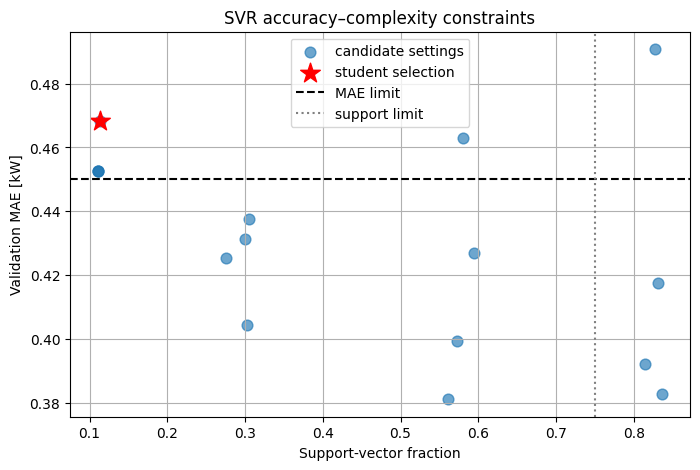

In [ ]:
def svr_search_3b():
    rows = []
    for C in [3, 10, 30, 100]:
        for epsilon in [0.10, 0.25, 0.50, 0.90]:
            model = build_svr_3a(True, C, epsilon, "scale")
            model.fit(fan_data.loc[fan_train_index, fan_numeric_features], fan_data.loc[fan_train_index, "power_kw"])
            pred = model.predict(fan_data.loc[fan_validation_index, fan_numeric_features])
            rows.append({
                "C": C, "epsilon": epsilon,
                "validation_MAE_kW": mean_absolute_error(fan_data.loc[fan_validation_index, "power_kw"], pred),
                "support_vectors": len(model.named_steps["svr"].support_),
                "support_fraction": len(model.named_steps["svr"].support_) / len(fan_train_index),
            })
    return pd.DataFrame(rows)


svr_candidates_3b = svr_search_3b()
display(svr_candidates_3b.sort_values("validation_MAE_kW"))

selected_C_3b = 3.0       # TODO: replace using both constraints
selected_epsilon_3b = 0.9 # TODO: replace using both constraints
selected_svr_row_3b = svr_candidates_3b[
    (svr_candidates_3b["C"] == selected_C_3b)
    & (svr_candidates_3b["epsilon"] == selected_epsilon_3b)
]
display(selected_svr_row_3b)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(
    svr_candidates_3b["support_fraction"],
    svr_candidates_3b["validation_MAE_kW"],
    s=60,
    alpha=0.65,
    label="candidate settings",
)
ax.scatter(
    selected_svr_row_3b["support_fraction"],
    selected_svr_row_3b["validation_MAE_kW"],
    marker="*", s=220, color="red", label="student selection",
)
ax.axhline(0.45, color="black", linestyle="--", label="MAE limit")
ax.axvline(0.75, color="grey", linestyle=":", label="support limit")
ax.set(xlabel="Support-vector fraction", ylabel="Validation MAE [kW]", title="SVR accuracy–complexity constraints")
ax.grid(True); ax.legend(); plt.show()


**Your answer:** report your `C`, `epsilon`, validation MAE and support fraction. Explain the
trade-off represented by the support-vector constraint.


## Activity 4B — Select a repeatable neural network

**Problem:** compare three architectures across three random seeds. Select a model using both
mean validation MAE and seed-to-seed standard deviation. Prefer the smaller architecture when
evidence is effectively tied.

**Hints:**

1. Rank architectures by mean MAE; do not rank the individual seed rows.
2. Treat architectures within `0.02 kW` of the lowest mean as practically similar for this
   exercise.
3. Within that near-best set, inspect the standard deviation and total hidden-neuron count.
4. Prefer the smaller architecture unless its variability is materially worse.
5. State the number of hidden layers and neurons in your final choice.

In the plot, each point is the mean validation MAE and each vertical bar shows one standard
deviation across the three seeds.


,architecture,seed,validation_MAE_kW,iterations
0,"(10,)",541,0.373,498
1,"(10,)",542,0.396,718
2,"(10,)",543,0.406,327
3,"(30,)",541,0.367,439
4,"(30,)",542,0.383,485
5,"(30,)",543,0.382,323
6,"(30, 15)",541,0.389,164
7,"(30, 15)",542,0.384,232
8,"(30, 15)",543,0.390,179


,mean,std,min,max
architecture,,,,
"(10,)",0.392,0.017,0.373,0.406
"(30, 15)",0.388,0.004,0.384,0.390
"(30,)",0.378,0.009,0.367,0.383


,mean,std,min,max
architecture,,,,
"(10,)",0.392,0.017,0.373,0.406


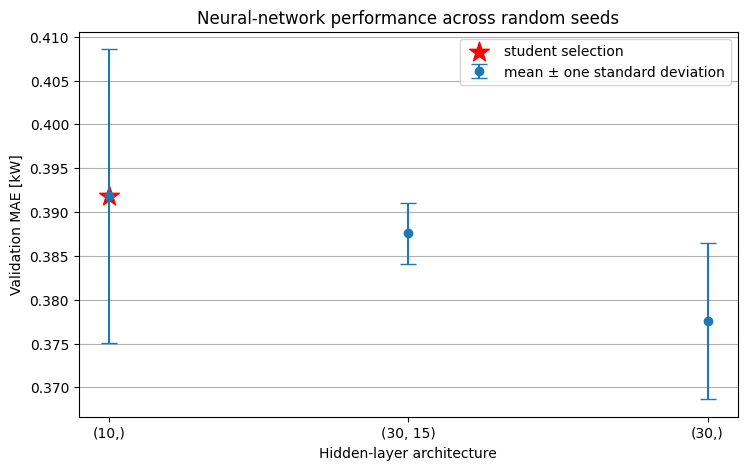

In [ ]:
architectures_4b = [(10,), (30,), (30, 15)]
seeds_4b = [541, 542, 543]
rows_4b = []
for architecture in architectures_4b:
    for seed in seeds_4b:
        candidate = build_mlp_4a(architecture, alpha=0.001, seed=seed)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            candidate.fit(fan_data.loc[fan_train_index, fan_numeric_features], fan_data.loc[fan_train_index, "power_kw"])
        pred = candidate.predict(fan_data.loc[fan_validation_index, fan_numeric_features])
        rows_4b.append({
            "architecture": str(architecture), "seed": seed,
            "validation_MAE_kW": mean_absolute_error(fan_data.loc[fan_validation_index, "power_kw"], pred),
            "iterations": candidate.named_steps["mlp"].n_iter_,
        })

mlp_repeats_4b = pd.DataFrame(rows_4b)
mlp_summary_4b = mlp_repeats_4b.groupby("architecture")["validation_MAE_kW"].agg(["mean", "std", "min", "max"])
display(mlp_repeats_4b)
display(mlp_summary_4b)

selected_architecture_4b = "(10,)"  # TODO: replace and justify
display(mlp_summary_4b.loc[[selected_architecture_4b]])

architecture_order_4b = list(mlp_summary_4b.index)
x_4b = np.arange(len(architecture_order_4b))
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.errorbar(
    x_4b,
    mlp_summary_4b.loc[architecture_order_4b, "mean"],
    yerr=mlp_summary_4b.loc[architecture_order_4b, "std"],
    fmt="o", capsize=6, label="mean ± one standard deviation",
)
selected_x_4b = architecture_order_4b.index(selected_architecture_4b)
ax.scatter(
    selected_x_4b,
    mlp_summary_4b.loc[selected_architecture_4b, "mean"],
    marker="*", s=220, color="red", label="student selection",
)
ax.set_xticks(x_4b, architecture_order_4b)
ax.set(xlabel="Hidden-layer architecture", ylabel="Validation MAE [kW]", title="Neural-network performance across random seeds")
ax.grid(True, axis="y"); ax.legend(); plt.show()


**Your answer:** identify the selected architecture, its mean and standard deviation, and why
you did not simply select the single lowest-MAE run.


## Activity 5B — Select a model when underprediction is costly

**Problem:** three models predict fan power for eight critical high-load runs. A 1 kW
underprediction costs four times as much as a 1 kW overprediction because underestimated demand
may overload the planned electrical supply.

Select a model using MAE, RMSE, underprediction rate and the supplied asymmetric cost.

**Hints:**

1. Residual = observed − predicted; positive residuals are underpredictions.
2. For example, observed `14 kW` and predicted `13 kW` gives residual `+1 kW`, so its cost is
   `4 × 1 = 4` cost units. Predicting `15 kW` gives residual `−1 kW` and costs `1` unit.
3. Rank the models by `asymmetric_cost`, then check MAE and RMSE so the trade-off is visible.
4. Do not select using R² alone on this small critical subset.
5. State whether the additional conservative bias is acceptable.


,MAE_kW,RMSE_kW,underprediction_rate,asymmetric_cost
model,,,,
mean baseline,1.188,1.398,0.5,3.438
lowest MAE,0.525,0.548,0.5,1.500
conservative,0.813,0.816,0.0,0.813


Selected model: lowest MAE


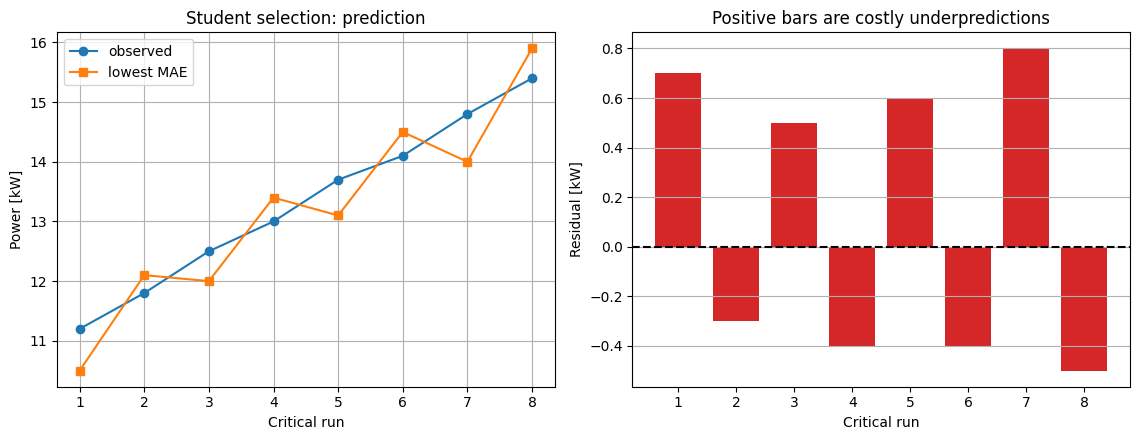

In [ ]:
observed_5b = np.array([11.2, 11.8, 12.5, 13.0, 13.7, 14.1, 14.8, 15.4])
candidate_predictions_5b = {
    "mean baseline": np.full(8, 13.0),
    "lowest MAE": observed_5b + np.array([-0.7, 0.3, -0.5, 0.4, -0.6, 0.4, -0.8, 0.5]),
    "conservative": observed_5b + np.array([0.8, 0.9, 0.7, 0.8, 0.9, 0.7, 0.8, 0.9]),
}

def consequence_metrics_5b(y_true, predictions):
    rows = []
    for name, pred in predictions.items():
        residual = y_true - pred
        asymmetric_cost = np.mean(np.where(residual > 0, 4 * residual, np.abs(residual)))
        rows.append({
            "model": name,
            "MAE_kW": mean_absolute_error(y_true, pred),
            "RMSE_kW": root_mean_squared_error(y_true, pred),
            "underprediction_rate": np.mean(residual > 0),
            "asymmetric_cost": asymmetric_cost,
        })
    return pd.DataFrame(rows).set_index("model")


decision_table_5b = consequence_metrics_5b(observed_5b, candidate_predictions_5b)
display(decision_table_5b)

selected_model_5b = "lowest MAE"  # TODO: select for the stated consequence
print("Selected model:", selected_model_5b)

def plot_choice_5b(model_name, colour, title):
    prediction = candidate_predictions_5b[model_name]
    residual = observed_5b - prediction
    runs = np.arange(1, len(observed_5b) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
    axes[0].plot(runs, observed_5b, marker="o", label="observed")
    axes[0].plot(runs, prediction, marker="s", label=model_name)
    axes[0].set(xlabel="Critical run", ylabel="Power [kW]", title=f"{title}: prediction")
    axes[0].grid(True); axes[0].legend()
    axes[1].bar(runs, residual, color=colour)
    axes[1].axhline(0, color="black", linestyle="--")
    axes[1].set(xlabel="Critical run", ylabel="Residual [kW]", title="Positive bars are costly underpredictions")
    axes[1].grid(True, axis="y")
    fig.tight_layout(); plt.show()


plot_choice_5b(selected_model_5b, "tab:red", "Student selection")


**Your answer:** name the selected model and cite at least two metrics. Explain why the model
with the lowest MAE may not minimise the engineering consequence.


## Activity 6B — Audit data for a model deployed to an unseen fan

**Prediction task:** before a run begins, predict its mean power for a newly installed fan unit.

The received file contains duplicated events, some airflow values recorded in L/s but labelled
m³/s, missing sensors, and post-run measurements. The starter choices run and may score well,
but they do not yet match the task.

**Hints:**

Work through the decisions in this order:

| Decision | Question to answer | Relevant starter variable |
|---|---|---|
| Event identity | Should copied `event_id` values count as new evidence? | `remove_duplicates_6b` |
| Validity rule | Should airflow outside the declared 2–8 m³/s range enter the model? | `apply_validity_rule_6b` |
| Feature availability | Which fields genuinely exist before the run starts? | `selected_features_6b` |
| Deployment split | How do we simulate prediction for a newly installed physical fan? | `selected_split_6b` |

A defensible final plot should show **zero fan units shared** between training and validation.


,count
rows,525
unique_events,480
duplicate_event_rows,45
invalid_airflow_rows,8
missing_temperature_rows,12
missing_vibration_rows,16


,result
rows_used,525.000
shared_units,8.000
MAE,0.288
RMSE,0.558
R2,0.923


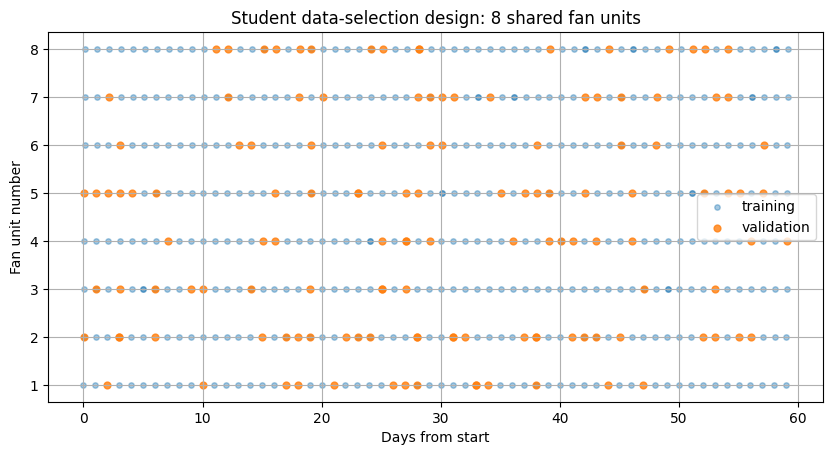

In [ ]:
rng_6b = np.random.default_rng(5606)
duplicate_6b = fan_data.sample(45, random_state=56)
received_6b = pd.concat([fan_data, duplicate_6b], ignore_index=True)
bad_flow_rows_6b = rng_6b.choice(received_6b.index[received_6b["airflow_m3s"] < 7.0], 8, replace=False)
received_6b.loc[bad_flow_rows_6b, "airflow_m3s"] *= 1000  # L/s stored in the m³/s column

def audit_summary_6b(data):
    return pd.Series({
        "rows": len(data),
        "unique_events": data["event_id"].nunique(),
        "duplicate_event_rows": data.duplicated("event_id").sum(),
        "invalid_airflow_rows": (~data["airflow_m3s"].between(2, 8)).sum(),
        "missing_temperature_rows": data["ambient_temp_c"].isna().sum(),
        "missing_vibration_rows": data["vibration_mm_s"].isna().sum(),
    }, name="count").to_frame()


def prepare_choice_6b(split_kind, remove_duplicates, apply_validity_rule):
    data = received_6b.copy()
    if remove_duplicates:
        data = data.drop_duplicates("event_id")
    if apply_validity_rule:
        data = data[data["airflow_m3s"].between(2, 8)]
    data = data.reset_index(drop=True)
    train_rows, validation_rows = make_split_6a(data, split_kind)
    return data, np.asarray(train_rows), np.asarray(validation_rows)


def evaluate_choice_6b(feature_names, split_kind, remove_duplicates, apply_validity_rule):
    data, train_rows, validation_rows = prepare_choice_6b(
        split_kind, remove_duplicates, apply_validity_rule
    )
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("svr", SVR(C=30, epsilon=0.25)),
    ])
    model.fit(data.iloc[train_rows][feature_names], data.iloc[train_rows]["power_kw"])
    pred = model.predict(data.iloc[validation_rows][feature_names])
    return pd.Series({
        "rows_used": len(data),
        "shared_units": len(set(data.iloc[train_rows]["unit_id"]) & set(data.iloc[validation_rows]["unit_id"])),
        **regression_metrics(data.iloc[validation_rows]["power_kw"], pred),
    }, name="result").to_frame()


def plot_split_choice_6b(split_kind, remove_duplicates, apply_validity_rule, title):
    data, train_rows, validation_rows = prepare_choice_6b(
        split_kind, remove_duplicates, apply_validity_rule
    )
    day = (data["timestamp"] - data["timestamp"].min()).dt.total_seconds() / 86400
    unit_number = data["unit_id"].str[1:].astype(int)
    shared_units = len(set(data.iloc[train_rows]["unit_id"]) & set(data.iloc[validation_rows]["unit_id"]))
    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.scatter(day.iloc[train_rows], unit_number.iloc[train_rows], s=15, alpha=0.4, label="training")
    ax.scatter(day.iloc[validation_rows], unit_number.iloc[validation_rows], s=24, alpha=0.8, label="validation")
    ax.set(
        xlabel="Days from start", ylabel="Fan unit number",
        title=f"{title}: {shared_units} shared fan units",
    )
    ax.set_yticks(range(1, 9)); ax.grid(True); ax.legend(); plt.show()


display(audit_summary_6b(received_6b))

# TODO: replace all four starter decisions so they match the prediction task.
selected_features_6b = fan_numeric_features + ["run_duration_h", "post_run_energy_kwh"]
selected_split_6b = "random"
remove_duplicates_6b = False
apply_validity_rule_6b = False

display(evaluate_choice_6b(
    selected_features_6b, selected_split_6b,
    remove_duplicates_6b, apply_validity_rule_6b,
))
plot_split_choice_6b(
    selected_split_6b, remove_duplicates_6b, apply_validity_rule_6b,
    "Student data-selection design",
)


**Your answer:** list the four corrected decisions. Report the resulting MAE and number of
shared units. Explain why the starter score is not valid evidence for a newly installed fan.


# ⬛ Revision and home study

Complete unfinished B activities before attempting the questions below. Answers should refer to
evidence, units, deployment conditions and consequences—not only the name of an algorithm.


## 📝 Activity 7 — Test-style short problems

1. A fitted model is `power = 1.8 + 0.7 flow + 0.04 flow²`. Explain why this is linear in its
   coefficients even though its graph is curved.
2. A tree has training MAE `0.05 kW` and validation MAE `1.8 kW`. Diagnose the likely problem
   and name one hyperparameter change.
3. An RBF SVR uses pressure in Pa and vibration in mm/s without scaling. Explain the risk.
4. Increasing `epsilon` reduces the support-vector count and slightly increases MAE. State the
   trade-off.
5. Two neural-network seeds produce MAE values `0.38` and `1.10 kW`. What additional evidence
   should be collected before reporting performance?
6. Model A has lower MAE; Model B has lower RMSE. Give one error pattern that could produce this
   ranking difference.
7. Why must a baseline be fitted using training targets rather than validation targets?
8. A dataset contains ten readings from each of 20 bearings. The model will be deployed to new
   bearings. Choose a split and identify the grouping key.
9. A feature is the inspection outcome entered after a failure prediction was requested. Name
   the problem and the required action.
10. A model is trained on winter operation and deployed in summer. Name two checks required
    before trusting its predictions.
11. Explain why removing every statistical outlier can make an engineering model less useful.
12. State the difference between a validation set used for model selection and a final test set.


## 🧪 Activity 8 — Integrated model-selection challenge

Using the fixed fan training and validation rows, compare a mean baseline, linear regression,
decision tree and scaled SVR. The helper code below fits all four.

**Your task:** choose one model for represented fan units. Your report must include:

- MAE, RMSE and R² relative to the baseline;
- one complexity or interpretability consideration;
- one residual or operating-region check you would add; and
- one reason this random-row result does not demonstrate transfer to a new fan.


In [ ]:
models_8 = {
    "mean baseline": DummyRegressor(strategy="mean"),
    "linear": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("linear", LinearRegression()),
    ]),
    "tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("tree", DecisionTreeRegressor(max_depth=5, min_samples_leaf=8, random_state=58)),
    ]),
    "scaled SVR": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("svr", SVR(C=30, epsilon=0.25)),
    ]),
}

predictions_8 = {}
for name, model in models_8.items():
    model.fit(fan_data.loc[fan_train_index, fan_numeric_features], fan_data.loc[fan_train_index, "power_kw"])
    predictions_8[name] = model.predict(fan_data.loc[fan_validation_index, fan_numeric_features])

comparison_8 = metric_table(fan_data.loc[fan_validation_index, "power_kw"], predictions_8)
display(comparison_8.sort_values("MAE"))

selected_model_8 = "mean baseline"  # TODO: replace and justify in your report
print("Selected model:", selected_model_8)


,MAE,RMSE,R2
tree,0.363,0.458,9.371e-01
linear,0.372,0.476,9.323e-01
scaled SVR,0.427,0.632,8.806e-01
mean baseline,1.484,1.828,-7.010e-04


Selected model: mean baseline


# 🔗 Project bridge

For your own engineering dataset, write a six-line plan:

1. unit of observation;
2. target and prediction time;
3. features genuinely available at that time;
4. baseline and candidate models;
5. split strategy matching deployment; and
6. metrics, critical operating regions and failure consequences.

Add one sentence describing what new evidence would cause you to reject or retrain the model.


# ✅ Week 5 completion checklist

- [ ] I changed and explained every guided `TODO` in Activities 1A–6A.
- [ ] I completed and justified every problem in Activities 1B–6B.
- [ ] I can distinguish linearity in coefficients from curvature in an input.
- [ ] I can explain tree, SVR and neural-network complexity controls.
- [ ] I can choose metrics from engineering consequences rather than convenience.
- [ ] I can identify target leakage and preprocessing leakage.
- [ ] I can choose random, grouped or time-ordered evaluation from the deployment task.
- [ ] I completed the short problems and integrated challenge without copying a solution.


# 📚 References and data provenance

Method definitions and APIs follow the official scikit-learn documentation for linear models,
decision trees, support-vector machines, neural networks, model evaluation, pipelines and
model-selection splitters.

All fan, calibration and prediction datasets in this workbook are synthetic, deterministic and
generated in code. They are designed to reveal particular learning behaviours and are not
measurements from real equipment.

# 🤖 AI acknowledgement

Generative AI assisted with drafting, code development and editorial review. Activities,
numerical behaviour and tutor solutions were checked for alignment with the approved Week 5
notes and unit learning outcomes.
